# Règles de décision : EDT, CDT, CCDT et la lignée UDT

**Sous-série de l'arc [Théorie de la Décision](../README.md), après le pont causal
[Causal-Bridges](../Causal-Bridges/README.md).**

Un même problème de décision peut recevoir plusieurs réponses « rationnelles ». Ce carnet les
rend **comparables dans un seul objet** : un modèle causal structurel (SCM) fini, énuméré
exactement, sur lequel on sait faire trois choses distinctes —

1. **conditionner** sur l'acte : $P(O \mid A=a)$ — c'est la théorie de la décision **évidentielle**
   (EDT) ;
2. **intervenir** sur l'acte : $P(O \mid do(A=a))$ — c'est la théorie **causale** (CDT) ;
3. **intervenir sur la procédure** qui produit l'acte : $P(O \mid do(D=d))$ — c'est la lecture
   causale de la lignée **UDT/FDT**, qui choisit une politique avant d'observer.

Sur cette armature, le carnet **mesure** trois affirmations publiées au lieu de les répéter :

| Affirmation | Source archivée | Ce que le carnet calcule |
|---|---|---|
| CCDT donne 5 et 8 dans le cas ordinaire du tabagisme, et **encore 5 et 8** dans le cas de Fisher | Mohajeri (2023 ; publié 2024), équations (4), (5), (8), (9) | reproduction des quatre valeurs par la formule (1) |
| CCDT **se réduit à EDT** dans tout problème « adéquatement spécifié » | Mohajeri (2023 ; publié 2024), §5 | égalité des poids, monde par monde, plus une classe de mondes générés ; et la classe où l'argument n'a plus prise |
| Dans une population surtout TDT/UDT avec quelques agents CDT, **les agents CDT s'en sortent mieux** | Dai (2023), problème n° 4 (« 2TDT-1CDT ») | gains moyens par type, et la frontière où l'avantage disparaît |

**Prérequis** : probabilités conditionnelles ; la distinction $P(Y\mid X)$ / $P(Y\mid do(X))$
(revue dans [CausalBridges-00](../Causal-Bridges/CausalBridges-00-PearlLadder-Intro-Python.ipynb)).
Aucune clé d'API, aucun GPU : tout est calcul exact ou simulation seedée, plus une estimation
`dowhy` sur données simulées.

**Ce que ce carnet ne prétend pas** : trancher la philosophie. Il exhibe des conséquences
chiffrées de définitions précises. Les choix de modélisation (payoffs, corrélations, ce qui compte
comme « composante causée ») sont écrits dans le code et discutés, pas dissimulés.


In [1]:
# Un SCM fini se prête au calcul exact : on énumère la loi jointe au lieu d'échantillonner.
from __future__ import annotations

import itertools
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 160)


def det(valeur, domaine=(0, 1)):
    """Distribution déterministe qui déclare TOUT le domaine (utile à l'énumération des mondes)."""
    return {v: (1.0 if v == valeur else 0.0) for v in domaine}


@dataclass(frozen=True)
class Variable:
    """Variable discrète. cpt : {tuple des valeurs des parents -> {valeur: probabilité}}."""

    name: str
    parents: tuple
    cpt: dict


class SCM:
    """Modèle causal structurel fini, en ordre topologique.

    Deux lectures d'un même objet :
      - prob(query, given={A: a})  -> P(query | A=a)      (observation)
      - prob(query, do={A: a})     -> P(query | do(A=a))  (intervention : on coupe les
        arêtes entrantes de A et on fige sa valeur)
    Les bruits des mécanismes sont des variables explicites (U_*), de sorte que les mécanismes
    non racines sont déterministes : le contrefactuel individuel est alors bien défini.
    """

    def __init__(self, variables):
        self.variables = list(variables)
        self.names = [v.name for v in self.variables]
        seen = set()
        for v in self.variables:
            for p in v.parents:
                assert p in seen, f"{v.name} : parent {p} non déclaré avant (ordre topologique)"
            for key, dist in v.cpt.items():
                assert len(key) == len(v.parents), f"{v.name} : clé {key} mal dimensionnée"
                assert abs(sum(dist.values()) - 1.0) < 1e-9, f"{v.name} : loi non normalisée {dist}"
            seen.add(v.name)

    def joint(self, do=None):
        """Loi jointe exacte (éventuellement interventionnelle) : une ligne par monde."""
        do = do or {}
        domains = []
        for v in self.variables:
            values = sorted({val for dist in v.cpt.values() for val in dist})
            domains.append(values)
        rows = []
        for assignment in itertools.product(*domains):
            monde = dict(zip(self.names, assignment))
            p = 1.0
            for v in self.variables:
                if v.name in do:
                    p *= 1.0 if monde[v.name] == do[v.name] else 0.0
                    continue
                key = tuple(monde[parent] for parent in v.parents)
                p *= v.cpt[key][monde[v.name]]
            if p > 0:
                rows.append({**monde, "p": p})
        table = pd.DataFrame(rows)
        total = table["p"].sum()
        assert abs(total - 1.0) < 1e-9, f"loi jointe non normalisée : {total}"
        return table

    def prob(self, query, given=None, do=None):
        table = self.joint(do=do)
        if given:
            mask = np.ones(len(table), dtype=bool)
            for var, val in given.items():
                mask &= (table[var] == val).to_numpy()
            table = table[mask]
        if not query:
            return float(table["p"].sum())
        mask = np.ones(len(table), dtype=bool)
        for var, val in query.items():
            mask &= (table[var] == val).to_numpy()
        denom = table["p"].sum()
        assert denom > 0, f"conditionnement impossible : {given} sous do={do}"
        return float(table.loc[mask, "p"].sum() / denom)


def intervention_individuelle(scm, monde, acte, valeur):
    """Contrefactuel individuel : on impose l'acte, on conserve les exogènes (abduction).

    Les variables sans parent sont les exogènes ; les autres sont déterminées par leurs parents.
    On propage donc dans l'ordre topologique : abduction, action, prédiction.
    """
    nouveau = dict(monde)
    nouveau.pop("p", None)
    for v in scm.variables:
        if v.name == acte:
            nouveau[v.name] = valeur
            continue
        if not v.parents:
            continue  # exogène : inchangé par abduction
        key = tuple(nouveau[parent] for parent in v.parents)
        positifs = [val for val, p in v.cpt[key].items() if p > 0]
        assert len(positifs) == 1, f"{v.name} : mécanisme stochastique, abduction non triviale"
        nouveau[v.name] = positifs[0]
    return nouveau


print("Armature SCM prête : joint() énumère les mondes, prob() conditionne ou intervient,")
print("intervention_individuelle() calcule un contrefactuel à exogènes conservées.")
demo = SCM([
    Variable("X", (), {(): {0: 0.5, 1: 0.5}}),
    Variable("Y", ("X",), {(0,): {0: 0.9, 1: 0.1}, (1,): {0: 0.1, 1: 0.9}}),
])
print("Exemple minimal : X -> Y, avec P(Y=1|X)=0.9 si X=1, 0.1 sinon, P(X=1)=0.5.")
print(f"  P(Y=1 | X=1)      = {demo.prob({'Y': 1}, given={'X': 1}):.3f}")
print(f"  P(Y=1 | do(X=0))  = {demo.prob({'Y': 1}, do={'X': 0}):.3f}")


Armature SCM prête : joint() énumère les mondes, prob() conditionne ou intervient,
intervention_individuelle() calcule un contrefactuel à exogènes conservées.
Exemple minimal : X -> Y, avec P(Y=1|X)=0.9 si X=1, 0.1 sinon, P(X=1)=0.5.
  P(Y=1 | X=1)      = 0.900
  P(Y=1 | do(X=0))  = 0.100


## 1. Deux mondes que l'observation ne distingue pas

Le cas du tabagisme sert de banc d'essai depuis Fisher. On en utilise **deux versions**, avec
exactement les mêmes probabilités conditionnelles et les mêmes utilités :

| | cas **ordinaire** | cas de **Fisher** |
|---|---|---|
| ce qui cause le cancer | fumer ($S \to C$) | un gène ($G \to C$), fumer ne cause rien |
| ce qui cause le fait de fumer | le choix de l'agent ($S$ exogène) | le même gène ($G \to S$) |
| $P(C=1 \mid S=1)$ | 0,6 | 0,6 |
| $P(C=1 \mid S=0)$ | 0,2 | 0,2 |
| plaisir de fumer $J$ | $J = S$ | $J = S$ |

Les utilités sont celles du tableau 1 de Mohajeri (2023 ; publié 2024), repris d'Edgington (2011, p. 76) :
vie courte avec plaisir = 1, vie longue avec plaisir = 11, vie courte sans plaisir = 0,
vie longue sans plaisir = 10.

**Le point de toute la suite** : ces deux mondes sont *indiscernables à l'observation* — mêmes
$P(C \mid S)$ — mais pas à l'intervention. Dans le cas ordinaire, décider de fumer change le
risque ; dans le cas de Fisher, décider de fumer ne change que le plaisir. Une règle de décision
qui ne lit que les conditionnelles ne peut donc pas les traiter différemment. C'est précisément
ce que CDT fait et ce que EDT ne peut pas faire.


In [2]:
def monde_tabagisme(fisher: bool, prior: float = 0.5) -> SCM:
    """Deux mondes aux conditionnelles identiques, de causalité différente.

    Le bruit U_C (10 valeurs) rend les mécanismes déterministes :
    C = 1 si U_C < 6 (fumeur ou G=1), si U_C < 2 sinon.
    prior : P(S=1) dans le cas ordinaire, P(G=1) dans le cas de Fisher.
    """
    bruit_c = {(): {u: 0.1 for u in range(10)}}
    if fisher:
        # Gène -> tabac et gène -> cancer ; S n'a aucun effet sur C.
        cpt_c = {(g, u): det(1 if u < (6 if g == 1 else 2) else 0)
                 for g in (0, 1) for u in range(10)}
        return SCM([
            Variable("G", (), {(): {0: 1 - prior, 1: prior}}),
            Variable("S", ("G",), {(0,): det(0), (1,): det(1)}),
            Variable("U_C", (), bruit_c),
            Variable("C", ("G", "U_C"), cpt_c),
            Variable("J", ("S",), {(0,): det(0), (1,): det(1)}),
        ])
    # Choix -> tabac -> cancer ; pas de confondeur.
    cpt_c = {(s, u): det(1 if u < (6 if s == 1 else 2) else 0)
             for s in (0, 1) for u in range(10)}
    return SCM([
        Variable("S", (), {(): {0: 1 - prior, 1: prior}}),
        Variable("U_C", (), bruit_c),
        Variable("C", ("S", "U_C"), cpt_c),
        Variable("J", ("S",), {(0,): det(0), (1,): det(1)}),
    ])


ordinaire = monde_tabagisme(fisher=False)
fisher = monde_tabagisme(fisher=True)

for nom, monde in [("ordinaire", ordinaire), ("Fisher", fisher)]:
    print(f"--- cas {nom}")
    print(f"  P(C=1 | S=1) = {monde.prob({'C': 1}, given={'S': 1}):.2f}   "
          f"P(C=1 | S=0) = {monde.prob({'C': 1}, given={'S': 0}):.2f}   "
          f"P(C=1) = {monde.prob({'C': 1}):.2f}")
    print(f"  P(C=1 | do(S=1)) = {monde.prob({'C': 1}, do={'S': 1}):.2f}  "
          f"P(C=1 | do(S=0)) = {monde.prob({'C': 1}, do={'S': 0}):.2f}")

print("\nLoi jointe du cas de Fisher, margée sur le bruit U_C (mondes observables) :")
print(fisher.joint().groupby(["G", "S", "C", "J"], as_index=False)["p"].sum().to_string(index=False))


--- cas ordinaire
  P(C=1 | S=1) = 0.60   P(C=1 | S=0) = 0.20   P(C=1) = 0.40
  P(C=1 | do(S=1)) = 0.60  P(C=1 | do(S=0)) = 0.20
--- cas Fisher
  P(C=1 | S=1) = 0.60   P(C=1 | S=0) = 0.20   P(C=1) = 0.40
  P(C=1 | do(S=1)) = 0.40  P(C=1 | do(S=0)) = 0.40

Loi jointe du cas de Fisher, margée sur le bruit U_C (mondes observables) :
 G  S  C  J   p
 0  0  0  0 0.4
 0  0  1  0 0.1
 1  1  0  1 0.2
 1  1  1  1 0.3


### Lecture du résultat

Les deux mondes ont bien **les mêmes conditionnelles** (0,6 / 0,2) et la même marginale
$P(C=1)=0{,}4$ — et des interventions opposées :

| | $P(C=1 \mid do(S=1))$ | $P(C=1 \mid do(S=0))$ | effet causal du tabac |
|---|---|---|---|
| cas ordinaire | 0,60 | 0,20 | +0,40 |
| cas de Fisher | 0,40 | 0,40 | **0,00** |

Dans le cas de Fisher, $S$ et $C$ restent **associés** (les fumeurs ont 60 % de cancer) alors que
leur relation causale est nulle : toute l'association passe par le gène. C'est l'instance la plus
courte du confondement que toute la série Causal-Bridges instrumente.

Remarque de modélisation : on a choisi une population où $P(G=1)=0{,}5$ et $S=G$ (fumer est
déterminé par le gène). Ce choix reproduit les $P(C\mid S)$ de l'article ; il ne prétend pas
décrire une population réelle. La robustesse à ce choix est l'objet de l'exercice 1.


## 2. EDT et CDT : deux moyennes, deux réponses

Une règle de décision à la Savage attribue à chaque acte une **moyenne pondérée des utilités**
et recommande un acte maximal. Toute la divergence porte sur **les poids** :

$$\text{EDT}:\quad V(a)=\sum_o U(o)\,P(o \mid A=a)
\qquad\qquad
\text{CDT}:\quad V(a)=\sum_o U(o)\,P(o \mid do(A=a))$$

- **EDT** traite l'acte comme une **information** : « si j'apprends que je fume, qu'en attendre ? »
  Elle exploite donc toute corrélation, y compris celle qu'un confondeur produit.
- **CDT** traite l'acte comme une **intervention** : « si je décide de fumer, qu'est-ce que cela
  changera ? » Elle ignore la partie de la corrélation qui ne vient pas de l'acte.

Sur un SCM fini, les deux sont calculables exactement : on somme l'utilité sur les mondes de la
loi jointe, conditionnée ou mutilée. Écrivons ce moteur une fois, et appliquons-le aux deux cas.


In [3]:
def utilite_tabagisme(monde):
    """U = 10 * (1 - C) + J : vie longue = 10, plaisir de fumer = +1."""
    return 10.0 * (1 - monde["C"]) + monde["J"]


def esperance(scm, utilite, acte, valeur, mode):
    """Espérance d'utilité d'un acte, sous 'evidence' (EDT) ou 'intervention' (CDT)."""
    assert mode in {"evidence", "intervention"}
    table = scm.joint(do={acte: valeur} if mode == "intervention" else None)
    if mode == "evidence":
        table = table[table[acte] == valeur]
    poids = table["p"] / table["p"].sum()
    return float((poids * utilite(table)).sum())


def comparer_regles(scm, utilite, acte="S", valeurs=(0, 1)):
    lignes = []
    for mode, etiquette in [("evidence", "EDT"), ("intervention", "CDT")]:
        valeurs_calc = {a: esperance(scm, utilite, acte, a, mode) for a in valeurs}
        meilleur = max(valeurs_calc, key=valeurs_calc.get)
        lignes.append({"règle": etiquette,
                       **{f"V({acte}={a})": round(v, 6) for a, v in valeurs_calc.items()},
                       "recommande": f"{acte}={meilleur}"})
    return pd.DataFrame(lignes)


print("Utilités : U = 10 * (1 - C) + J  (vie courte avec plaisir = 1, longue avec plaisir = 11,")
print("          vie courte sans plaisir = 0, longue sans plaisir = 10)\n")
for nom, monde in [("cas ORDINAIRE (S -> C)", ordinaire), ("cas de FISHER (G -> S, G -> C)", fisher)]:
    print(f"=== {nom}")
    print(comparer_regles(monde, utilite_tabagisme).to_string(index=False), "\n")


Utilités : U = 10 * (1 - C) + J  (vie courte avec plaisir = 1, longue avec plaisir = 11,
          vie courte sans plaisir = 0, longue sans plaisir = 10)

=== cas ORDINAIRE (S -> C)
règle  V(S=0)  V(S=1) recommande
  EDT     8.0     5.0        S=0
  CDT     8.0     5.0        S=0 

=== cas de FISHER (G -> S, G -> C)
règle  V(S=0)  V(S=1) recommande
  EDT     8.0     5.0        S=0
  CDT     6.0     7.0        S=1 



In [4]:
print("Attendus publiés — cas ordinaire : CCDT donne V(fumer)=5 et V(arrêter)=8 (équations 4 et 5).")
print("Le moteur CDT ci-dessus donne les mêmes nombres dans ce cas, puisqu'il n'y a pas de confondeur.")
print("\nLecture :")
print("  - cas ordinaire : EDT et CDT recommandent d'ARRÊTER (8 > 5). Le tabac coûte de l'espérance")
print("    de vie pour 1 unité de plaisir ; corrélation et causalité pointent dans le même sens.")
print("  - cas de Fisher : EDT recommande encore d'ARRÊTER (8 > 5), CDT recommande de FUMER (7 > 6).")
print("    Sous do(S), le cancer retombe à sa marginale 0,4 : seule la joie différencie les actes,")
print("    et CDT est la seule des deux à le voir.")
print("\nCe n'est pas un désaccord sur les chiffres : c'est un désaccord sur l'objet évalué.")


Attendus publiés — cas ordinaire : CCDT donne V(fumer)=5 et V(arrêter)=8 (équations 4 et 5).


Le moteur CDT ci-dessus donne les mêmes nombres dans ce cas, puisqu'il n'y a pas de confondeur.

Lecture :
  - cas ordinaire : EDT et CDT recommandent d'ARRÊTER (8 > 5). Le tabac coûte de l'espérance
    de vie pour 1 unité de plaisir ; corrélation et causalité pointent dans le même sens.
  - cas de Fisher : EDT recommande encore d'ARRÊTER (8 > 5), CDT recommande de FUMER (7 > 6).
    Sous do(S), le cancer retombe à sa marginale 0,4 : seule la joie différencie les actes,
    et CDT est la seule des deux à le voir.

Ce n'est pas un désaccord sur les chiffres : c'est un désaccord sur l'objet évalué.


## 3. Le même contraste mesuré par l'organe causal de la série

Le calcul exact ci-dessus connaît le monde. En pratique on n'a qu'un **échantillon**. Le pont avec
la série Causal-Bridges est immédiat : `dowhy` identifie l'estimande et l'estime, ici par
régression linéaire sur le traitement et le gène (le modèle est exactement linéaire, donc cet
estimateur est bien spécifié).

On simule les deux mondes, on estime l'effet de $S$ sur $C$ — et on compare au contraste
observationnel brut $E[C \mid S=1] - E[C \mid S=0]$. **Attendu** : 0,40 dans les deux mondes pour
le contraste brut ; 0,40 dans le cas ordinaire et **0,00** dans le cas de Fisher pour l'effet causal.


In [5]:
import warnings

import dowhy
from dowhy import CausalModel

warnings.filterwarnings("ignore", category=FutureWarning)


def echantillonner(scm, n, seed):
    """Échantillonne la loi jointe observée (sans intervention), exactement les mêmes variables."""
    rng = np.random.default_rng(seed)
    table = scm.joint()
    index = rng.choice(len(table), size=n, p=(table["p"] / table["p"].sum()).to_numpy())
    return table.iloc[index].drop(columns="p").reset_index(drop=True)


def effet_estime(data, traitement="S", resultat="C", confondeur=None):
    graphe = f"digraph {{ {confondeur} -> {traitement}; {confondeur} -> {resultat}; }}" if confondeur \
        else f"digraph {{ {traitement} -> {resultat}; }}"
    modele = CausalModel(data=data, treatment=traitement, outcome=resultat,
                         graph=graphe, proceed_when_unidentifiable=True)
    estimande = modele.identify_effect(proceed_when_unidentifiable=True)
    estimation = modele.estimate_effect(estimande, method_name="backdoor.linear_regression",
                                        control_value=0, treatment_value=1)
    return float(estimation.value)


N = 4000
resultats = []
for nom, monde, confondeur in [("ordinaire", ordinaire, None), ("Fisher", fisher, "G")]:
    donnees = echantillonner(monde, N, seed=2026)
    brut = float(donnees.loc[donnees["S"] == 1, "C"].mean() - donnees.loc[donnees["S"] == 0, "C"].mean())
    vrai = monde.prob({"C": 1}, do={"S": 1}) - monde.prob({"C": 1}, do={"S": 0})
    resultats.append({"monde": nom, "n": N,
                      "contraste brut E[C|S=1]-E[C|S=0]": round(brut, 4),
                      "effet causal vrai (SCM)": round(vrai, 4),
                      "ATE dowhy": round(effet_estime(donnees, confondeur=confondeur), 4)})

verdict_causal = pd.DataFrame(resultats)
print(verdict_causal.to_string(index=False))
print(f"\nVersion dowhy : {dowhy.__version__}")


    monde    n  contraste brut E[C|S=1]-E[C|S=0]  effet causal vrai (SCM)  ATE dowhy
ordinaire 4000                            0.4161                      0.4     0.4161
   Fisher 4000                            0.4161                      0.0     0.0000

Version dowhy : 0.14


### Lecture du résultat

Le contraste brut est **le même dans les deux mondes** (~0,40), et l'effet causal estimé par
`dowhy` les sépare : positif dans le cas ordinaire, **nul dans le cas de Fisher**. C'est la
signature du confondement, obtenue ici avec l'outil de la série plutôt qu'avec notre énumération.

Conséquence décisionnelle : une règle qui choisit sur la base du contraste brut **répète la même
recommandation dans deux mondes où l'action n'a pas le même effet**. EDT fait exactement cela
quand elle s'alimente de $P(C \mid S)$ seule.

Deux réserves honnêtes : l'estimation est bruitée (n = 4000), et elle suppose le **graphe connu**
— `dowhy` ne découvre pas ici que le gène confond, on le lui donne. Sans observation de $G$, le
cas de Fisher n'est pas identifiable : la distinction EDT/CDT n'est alors pas tranchable par les
données seules, ce qui est une raison de plus de traiter le choix de la règle comme un choix de
modélisation, pas comme une évidence empirique.


## 4. Le cas de Newcomb : la prédiction comme variable du monde

Le problème de Newcomb inverse la situation : maintenant c'est **EDT** qui semble donner la
réponse riche et **CDT** la réponse pauvre. Un prédicteur fiable $M$ a prévu votre choix ; deux
boîtes sont devant vous.

- boîte transparente : 1 000, toujours ;
- boîte opaque : 1 000 000 si le prédicteur a prévu « une seule boîte », 0 sinon.

Prendre **les deux boîtes** rapporte donc 1 000 **plus** le contenu de l'opaque ; prendre **une
seule boîte** rapporte le contenu de l'opaque seul. Le prédicteur **a déjà agi** : rien de ce que
vous faites ne change le contenu. Modélisons-le comme une variable du monde, avec la précision
$\pi$ comme paramètre :

$$D \to M,\qquad D \to A,\qquad M \to \text{gain} \leftarrow A$$

où $D$ est la disposition qui produit à la fois la prédiction et l'acte. L'acte ne cause **pas**
$M$ : il n'y a pas d'arête $A \to M$. CDT doit donc prendre les deux boîtes, quelle que soit la
fiabilité du prédicteur — tandis qu'EDT conditionne sur l'acte et récupère la corrélation.


In [6]:
def monde_newcomb(precision=0.9, disposition=0.5):
    """Newcomb : A=1 = une seule boîte (l'opaque), A=0 = les deux boîtes.

    D : disposition, produit l'acte ET la prédiction M. Le prédicteur est fiable avec
    probabilité `precision` ; son bruit U_M (10 valeurs) garde le mécanisme déterministe.
    La boîte opaque contient 1_000_000 si M=1, 0 sinon ; la transparente contient toujours 1000.
    """
    seuil = int(round(10 * precision))
    cpt_m = {}
    for d in (0, 1):
        for u in range(10):
            correct = (u < seuil) if d == 1 else (u >= seuil)
            cpt_m[(d, u)] = det(1 if correct else 0)
    return SCM([
        Variable("D", (), {(): {0: 1 - disposition, 1: disposition}}),
        Variable("A", ("D",), {(0,): det(0), (1,): det(1)}),
        Variable("U_M", (), {(): {u: 0.1 for u in range(10)}}),
        Variable("M", ("D", "U_M"), cpt_m),
    ])


def utilite_newcomb(monde):
    """Une boîte : 1_000_000 * M. Deux boîtes : 1000 + 1_000_000 * M (on garde le contenu !)."""
    opaque = 1_000_000.0 * monde["M"]
    return np.where(monde["A"] == 1, opaque, 1000.0 + opaque)


newcomb = monde_newcomb(precision=0.9)
print("Prédicteur fiable à 90 %. A=1 : une seule boîte ; A=0 : les deux (1000 + contenu opaque).")
print(f"P(M=1) = {newcomb.prob({'M': 1}):.2f} ; "
      f"P(M=1|A=1) = {newcomb.prob({'M': 1}, given={'A': 1}):.2f}\n")
print(comparer_regles(newcomb, utilite_newcomb, acte="A").to_string(index=False))

balayage = []
for precision in [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
    monde = monde_newcomb(precision=precision)
    edt1 = esperance(monde, utilite_newcomb, "A", 1, "evidence")
    edt0 = esperance(monde, utilite_newcomb, "A", 0, "evidence")
    balayage.append({"précision du prédicteur": precision,
                     "EDT V(une boîte)": round(edt1, 1),
                     "EDT V(deux boîtes)": round(edt0, 1),
                     "CDT V(une boîte)": round(esperance(monde, utilite_newcomb, "A", 1, "intervention"), 1),
                     "CDT V(deux boîtes)": round(esperance(monde, utilite_newcomb, "A", 0, "intervention"), 1),
                     "EDT choisit une boîte": bool(edt1 > edt0)})
print("\nSensibilité à la fiabilité du prédicteur :")
print(pd.DataFrame(balayage).to_string(index=False))
print("\nCDT choisit les deux boîtes à TOUTE précision : 1000 + espérance de l'opaque > espérance")
print("de l'opaque seul. C'est la dominance, et elle ne dépend pas du prédicteur.")


Prédicteur fiable à 90 %. A=1 : une seule boîte ; A=0 : les deux (1000 + contenu opaque).
P(M=1) = 0.50 ; P(M=1|A=1) = 0.90

règle   V(A=0)   V(A=1) recommande
  EDT 101000.0 900000.0        A=1
  CDT 501000.0 500000.0        A=0

Sensibilité à la fiabilité du prédicteur :
 précision du prédicteur  EDT V(une boîte)  EDT V(deux boîtes)  CDT V(une boîte)  CDT V(deux boîtes)  EDT choisit une boîte
                     0.5          500000.0            501000.0          500000.0            501000.0                  False
                     0.6          600000.0            401000.0          500000.0            501000.0                   True
                     0.7          700000.0            301000.0          500000.0            501000.0                   True
                     0.8          800000.0            201000.0          500000.0            501000.0                   True
                     0.9          900000.0            101000.0          500000.0            501000.0      

### Lecture du résultat

Deux observations que le tableau rend nettes.

1. **CDT prend les deux boîtes à toute précision du prédicteur**, par dominance : l'acte n'a
   aucun effet causal sur $M$, donc les deux boîtes rapportent toujours 1000 de plus que l'opaque
   seule. Aucune intervention ne peut augmenter le contenu d'une boîte déjà remplie.
2. **EDT prend une seule boîte dès que le prédicteur est un peu fiable**, parce que
   $P(M=1 \mid A=1)$ égale la précision : conditionner sur son acte, c'est apprendre ce que le
   prédicteur a fait. Son espérance croît avec la précision, comme l'intuition newcombienne le
   demande ; elle retombe sur les deux boîtes quand le prédicteur est au hasard (0,5).

Le carnet ne tranche pas entre ces réponses : il montre que le débat porte sur **le statut de la
corrélation entre votre acte et une prédiction déjà enregistrée**. La section suivante introduit
une troisième règle, CCDT, qui prétendait réconcilier les deux — et dont on va mesurer qu'elle
retombe sur EDT.


## 5. CCDT : conditionner sur la causalité, conséquence par conséquence

CDT et EDT divergent sur les poids. CCDT (Edgington 2011) prend le parti de garder la
**moyenne conditionnelle d'EDT** et de ne sommer que sur les **mondes adéquats**
(*adequate*) : ceux où l'acte est bien une cause de la conséquence obtenue. L'intuition
d'Edgington tient en une phrase : il ne suffit pas qu'un acte **corrèle** avec une
conséquence pour qu'elle compte, il faut que l'acte y soit pour quelque chose. Mohajeri
(2023 ; publié 2024) en donne la forme exploitable, sa formule (1) :

$$\text{CCDT}:\quad \text{EV}(a)=\sum_j P\big(a \triangleright C_j \mid a\big)\,U(C_j)$$

où $\triangleright$ se lit « l'acte $a$ **influence** la conséquence $C_j$ ». Deux écarts
avec la formule d'EDT de la section 2, et ce sont eux qui portent tout :

- le poids reste **conditionnel** — $P(C_j \mid a)$, jamais $P(C_j \mid do(a))$ : l'acte
  est supposé posé par le sujet, le monde n'est pas encore mutilé ;
- la somme est restreinte aux conséquences **influencées** : celles dont au moins une
  composante changerait si l'acte prenait une autre valeur.

Reste à fixer ce que « influencer » veut dire, et deux lectures de l'adéquation s'opposent :

1. *au niveau de l'acte* : l'acte est-il, globalement, une cause de la conséquence ? Une
   lecture par la manipulation suffirait — si $P(C \mid do(a)) \neq P(C)$, l'acte agit.
   Mais elle est tout ou rien : elle ne sait pas dire qu'une conséquence est causée *en
   partie*, ni traiter un cas où l'acte cause une composante (le plaisir de fumer) sans
   causer l'autre (la durée de vie).
2. *au niveau de la conséquence, sous $do(a)$* : en supposant l'acte posé, chaque conséquence
   possible contient-elle une composante qu'il cause ? C'est ce que fait Mohajeri : sous $S=1$,
   le plaisir $J$ est causé dans **tous** les mondes, donc $P(S\triangleright C_j \mid S)=P(C_j\mid S)$,
   et l'on retrouve $0{,}6\times1+0{,}4\times11=5$.

On implémente donc la lecture 2, avec un test **directionnel** : en partant d'un monde où l'acte
est posé ($do(a)$), imposer une autre valeur de l'acte changerait-il une composante de la
conséquence, à exogènes conservées ? C'est un contrefactuel individuel **sous $do(a)$**, et non
la question symétrique « l'alternative produirait-elle cette conséquence ? » — qui, elle,
résoudrait Newcomb par accident. Le bruit de chaque mécanisme est une variable explicite, ce qui
rend l'abduction bien définie.


In [7]:
def ev_ccdt_detail(scm, utilite, acte, valeur, composantes):
    """Formule (1) de Mohajeri : EV(a) = somme_j P(a influence C_j | a) * U(C_j).

    Lecture « sous do(a) », CONSÉQUENCE par conséquence (et non monde par monde) :
      - l'acte est posé par intervention ; on regroupe les mondes qui réalisent la même
        conséquence (les bruits U_* ne font pas partie de la description de la conséquence) ;
      - une conséquence est influencée si, dans un monde qui la réalise sous do(a), imposer une
        AUTRE valeur de l'acte changerait une de ses composantes, à exogènes conservées
        (contrefactuel sous do(a)) ;
      - le poids est la probabilité CONDITIONNELLE P(C_j | a), jamais P(C_j | do(a)).

    La direction compte : on ne demande pas « l'alternative produirait-elle cette conséquence ? »
    mais « quitter cette conséquence en changeant l'acte ? ». Dans Newcomb, changer d'acte ne
    change pas le contenu de la boîte : la conséquence n'est donc pas influencée.
    """
    domaine = sorted({val for v in scm.variables if v.name == acte
                      for dist in v.cpt.values() for val in dist})
    autres = [a for a in domaine if a != valeur]
    sous_acte = scm.joint(do={acte: valeur})
    cles = [c for c in sous_acte.columns if c not in {"p", acte} and not c.startswith("U_")]
    lignes = []
    for cons_tuple, groupe in sous_acte.groupby(cles, sort=True):
        cons = dict(zip(cles, cons_tuple))
        monde = {**groupe.iloc[0].to_dict()}
        monde.pop("p", None)
        p_cond = scm.prob(cons, given={acte: valeur})
        influencee, composante_causee = False, None
        for alt in autres:
            contrefactuel = intervention_individuelle(scm, dict(monde), acte, alt)
            for composante in composantes:
                if contrefactuel[composante] != monde[composante]:
                    influencee, composante_causee = True, composante
                    break
            if influencee:
                break
        u = float(utilite(pd.DataFrame([monde]))[0])
        lignes.append({**cons, "P(C|a)": round(p_cond, 6),
                       "composante causée": composante_causee,
                       "U": u, "contribution": p_cond * u * influencee})
    detail = pd.DataFrame(lignes)
    return float(detail["contribution"].sum()), detail


print("=== Fidélité : les quatre valeurs publiées par Mohajeri (2023 ; publié 2024) ===")
print("composantes retenues : C (vie courte/longue) et J (plaisir de fumer)\n")
attendus = {("ordinaire", 1): 5.0, ("ordinaire", 0): 8.0, ("Fisher", 1): 5.0, ("Fisher", 0): 8.0}
for (nom, valeur), attendu in attendus.items():
    monde = ordinaire if nom == "ordinaire" else fisher
    etiquette = "fumer" if valeur == 1 else "arrêter"
    calc, detail = ev_ccdt_detail(monde, utilite_tabagisme, "S", valeur, ("C", "J"))
    print(f"  {nom:9s} CCDT EV({etiquette:8s}) = {calc:6.3f}   publié = {attendu:5.1f}   "
          f"écart = {abs(calc - attendu):.2e}")
    if nom == "Fisher" and valeur == 1:
        print("  détail, cas de Fisher sous S=1 (une ligne par conséquence) :")
        print(detail.to_string(index=False))


=== Fidélité : les quatre valeurs publiées par Mohajeri (2023 ; publié 2024) ===
composantes retenues : C (vie courte/longue) et J (plaisir de fumer)

  ordinaire CCDT EV(fumer   ) =  5.000   publié =   5.0   écart = 0.00e+00
  ordinaire CCDT EV(arrêter ) =  8.000   publié =   8.0   écart = 0.00e+00
  Fisher    CCDT EV(fumer   ) =  5.000   publié =   5.0   écart = 0.00e+00
  détail, cas de Fisher sous S=1 (une ligne par conséquence) :
 G  C  J  P(C|a) composante causée    U  contribution
 0  0  1     0.0                 J 11.0           0.0
 0  1  1     0.0                 J  1.0           0.0
 1  0  1     0.4                 J 11.0           4.4
 1  1  1     0.6                 J  1.0           0.6
  Fisher    CCDT EV(arrêter ) =  8.000   publié =   8.0   écart = 0.00e+00


In [8]:
def ev_ccdt(scm, utilite, acte, valeur, composantes):
    return ev_ccdt_detail(scm, utilite, acte, valeur, composantes)[0]


def bilan_reduction(scm, utilite, acte, composantes, nom):
    """Compare CCDT, EDT et CDT acte par acte, et repère les conséquences non influencées."""
    domaine = sorted({val for v in scm.variables if v.name == acte
                      for dist in v.cpt.values() for val in dist})
    lignes, masse_non_adequate = [], 0.0
    for valeur in domaine:
        ccdt, detail = ev_ccdt_detail(scm, utilite, acte, valeur, composantes)
        edt = esperance(scm, utilite, acte, valeur, "evidence")
        cdt = esperance(scm, utilite, acte, valeur, "intervention")
        masse_non_adequate += float(detail.loc[detail["composante causée"].isna(), "P(C|a)"].sum())
        lignes.append({"acte": f"{acte}={valeur}", "CCDT": round(ccdt, 6),
                       "EDT": round(edt, 6), "CDT": round(cdt, 6),
                       "CCDT - EDT": round(ccdt - edt, 9)})
    print(f"=== {nom}")
    print(pd.DataFrame(lignes).to_string(index=False))
    print(f"  masse conditionnelle cumulée des conséquences SANS composante causée : "
          f"{masse_non_adequate:.4f}")
    return pd.DataFrame(lignes), masse_non_adequate


bilan_fisher, na_fisher = bilan_reduction(fisher, utilite_tabagisme, "S", ("C", "J"),
                                          "Fisher — chaque conséquence contient J=S")
print()
bilan_ord, na_ord = bilan_reduction(ordinaire, utilite_tabagisme, "S", ("C", "J"),
                                    "Ordinaire — idem")
print()
bilan_nc, na_nc = bilan_reduction(newcomb, utilite_newcomb, "A", ("M",),
                                  "Newcomb — la conséquence ne contient que M (contenu de la boîte)")
print("\nLe cas de Newcomb est le témoin négatif : l'acte ne cause RIEN dans sa conséquence,")
print("donc aucune conséquence n'est adéquate, et la formule (1) s'effondre à 0 au lieu de")
print("coïncider avec EDT.")


=== Fisher — chaque conséquence contient J=S
acte  CCDT  EDT  CDT  CCDT - EDT
 S=0   8.0  8.0  6.0         0.0
 S=1   5.0  5.0  7.0         0.0
  masse conditionnelle cumulée des conséquences SANS composante causée : 0.0000

=== Ordinaire — idem
acte  CCDT  EDT  CDT  CCDT - EDT
 S=0   8.0  8.0  8.0         0.0
 S=1   5.0  5.0  5.0         0.0
  masse conditionnelle cumulée des conséquences SANS composante causée : 0.0000



=== Newcomb — la conséquence ne contient que M (contenu de la boîte)
acte  CCDT      EDT      CDT  CCDT - EDT
 A=0   0.0 101000.0 501000.0   -101000.0
 A=1   0.0 900000.0 500000.0   -900000.0
  masse conditionnelle cumulée des conséquences SANS composante causée : 2.0000

Le cas de Newcomb est le témoin négatif : l'acte ne cause RIEN dans sa conséquence,
donc aucune conséquence n'est adéquate, et la formule (1) s'effondre à 0 au lieu de
coïncider avec EDT.


In [9]:
def fisher_parametre(rng):
    """Monde de Fisher aléatoire : le gène détermine le tabac, le cancer dépend du gène et d'un bruit.

    k : nombre de valeurs du bruit (U sur {0..9}) ; le cancer suit si U < k, avec k dépendant du
    gène. On ajoute une conséquence J=S (composante causée par l'acte) : adéquation garantie.
    """
    k0 = int(rng.integers(1, 5))
    k1 = int(rng.integers(k0 + 1, 10))
    prior = float(rng.uniform(0.2, 0.8))
    cpt_c = {(g, u): det(1 if u < (k1 if g == 1 else k0) else 0)
             for g in (0, 1) for u in range(10)}
    scm = SCM([
        Variable("G", (), {(): {0: 1 - prior, 1: prior}}),
        Variable("S", ("G",), {(0,): det(0), (1,): det(1)}),
        Variable("U_C", (), {(): {u: 0.1 for u in range(10)}}),
        Variable("C", ("G", "U_C"), cpt_c),
        Variable("J", ("S",), {(0,): det(0), (1,): det(1)}),
    ])
    longue_vie = float(rng.uniform(4.0, 20.0))
    plaisir = float(rng.uniform(0.5, 3.0))
    utilite = lambda m: longue_vie * (1 - m["C"]) + plaisir * m["J"]  # noqa: E731
    return scm, utilite, {"k0": k0, "k1": k1, "prior": round(prior, 3),
                          "U(vie longue)": round(longue_vie, 2), "U(plaisir)": round(plaisir, 2)}


rng = np.random.default_rng(14468)
ecarts_ccdt_edt, ecarts_cdt_edt, exemples = [], [], []
for _ in range(40):
    scm, utilite, params = fisher_parametre(rng)
    for valeur in (0, 1):
        ccdt = ev_ccdt(scm, utilite, "S", valeur, ("C", "J"))
        edt = esperance(scm, utilite, "S", valeur, "evidence")
        cdt = esperance(scm, utilite, "S", valeur, "intervention")
        ecarts_ccdt_edt.append(abs(ccdt - edt))
        ecarts_cdt_edt.append(abs(cdt - edt))
    if len(exemples) < 4:
        exemples.append(params)

print("40 mondes de Fisher générés (gène -> tabac, gène+bruit -> cancer, plaisir J=S), 80 actes évalués.")
print(f"  max |CCDT - EDT| = {max(ecarts_ccdt_edt):.3e}   <- la réduction tient sur toute la famille")
print(f"  max |CDT  - EDT| = {max(ecarts_cdt_edt):.3e}")
print(f"  actes où CDT diffère d'EDT de plus de 0,01 : "
      f"{sum(e > 0.01 for e in ecarts_cdt_edt)}/80")
print("\nQuatre mondes tirés (k0/k1 = seuils de bruit du cancer selon G=0/G=1) :")
print(pd.DataFrame(exemples).to_string(index=False))
print("\nLa réduction CCDT = EDT n'est donc pas un accident du chiffre 0,6/0,2 : elle tient sur")
print("toute une famille où CDT, elle, s'écarte d'EDT — c'est bien CCDT qui retombe sur EDT.")


40 mondes de Fisher générés (gène -> tabac, gène+bruit -> cancer, plaisir J=S), 80 actes évalués.
  max |CCDT - EDT| = 3.553e-15   <- la réduction tient sur toute la famille
  max |CDT  - EDT| = 9.030e+00
  actes où CDT diffère d'EDT de plus de 0,01 : 80/80

Quatre mondes tirés (k0/k1 = seuils de bruit du cancer selon G=0/G=1) :
 k0  k1  prior  U(vie longue)  U(plaisir)
  3   6  0.280          18.53        2.98
  2   6  0.543          18.54        0.95
  3   5  0.222          13.76        2.88
  1   2  0.683          13.15        2.47

La réduction CCDT = EDT n'est donc pas un accident du chiffre 0,6/0,2 : elle tient sur
toute une famille où CDT, elle, s'écarte d'EDT — c'est bien CCDT qui retombe sur EDT.


### Lecture du résultat — ce que la réduction dit, et ce qu'elle ne dit pas

Sur les deux cas du tabagisme, **CCDT = EDT acte par acte**, et les mondes non adéquats ont une
masse nulle : chaque conséquence contient le plaisir $J=S$, qui est causé par l'acte. Le test
d'influence ne retire donc aucun monde, et la formule (1) redonne exactement la moyenne
conditionnelle d'EDT. C'est le mécanisme de la réduction du §5 de Mohajeri, rendu visible :
l'argument n'a **rien de causal dans les poids**, il ne fait que filtrer des mondes — et quand
chaque conséquence contient une composante causée, le filtre est vide.

Sur Newcomb, en revanche, la conséquence ne contient que $M$ (le contenu de la boîte), que
l'acte ne cause pas : **tous les mondes sont non adéquats**, et notre implémentation de la
formule (1) s'effondre à 0. Ce n'est pas une réfutation de Mohajeri — c'est exactement la
restriction qu'il énonce : la réduction vaut pour les problèmes **adéquatement spécifiés**, et
Newcomb ne l'est pas si l'on décrit la conséquence uniquement par le contenu de la boîte. Pour
retrouver l'adéquation, il faudrait enrichir la description de la conséquence (par exemple y
inclure l'acte lui-même, ou le « choix d'une seule boîte » comme composante) — ce qui est
précisément le geste de modélisation que la notion d'adéquation laisse à la charge de
l'utilisateur.

**Leçon de modélisation** : « CCDT = EDT » n'est pas une identité magique entre deux théories,
c'est une identité **conditionnée à une façon de décrire les conséquences**. Le code le montre
mieux qu'un slogan : changez les composantes retenues, et l'identité peut disparaître (exercice 2).


## 6. Le cas d'Egan : pourquoi CCDT avait été inventée

Mohajeri rappelle en introduction qu'Egan (2007) a construit des **contre-exemples à CDT**, et que
CCDT (Edgington 2011) et la Benchmark Theory (Wedgwood 2013) visent à y répondre. Le schéma
d'Egan : votre acte est une **preuve sur vous-même**, pas une cause de ce qui vous arrive.

Version chiffrée utilisée ici (paramétrage de notre part, la structure est celle d'Egan) : un
bouton élimine tous les psychopathes. Vous êtes presque sûr de ne pas en être un
($P(D=1)=0{,}1$), mais **seul un psychopathe appuierait** ($A=D$). Appuyer rapporte +1000 si
vous n'êtes pas psychopathe, et vous coûte -1000 si vous l'êtes (vous disparaissez avec les
autres) ; ne pas appuyer vaut 0.

- **CDT** raisonne sous $do(A=1)$ : appuyer ne change pas ce que vous êtes, donc l'espérance vaut
  $0{,}9 \times 1000 + 0{,}1 \times (-1000) = +800$ → **appuyez**.
- **EDT** conditionne : appuyer prouve que vous êtes psychopathe → $-1000$ → **n'appuyez pas**.

Le jugement pré-théorique invoqué par Egan est « n'appuyez pas ». CCDT fut présentée comme une
CDT capable de le retrouver. Mesurons ce que notre implémentation en fait.


In [10]:
def monde_egan(prior=0.1):
    """D=1 : psychopathe ; A=D : seul un psychopathe appuie ; E : psychopathes éliminés ;
    L : vous disparaissez (si A=1 et D=1)."""
    return SCM([
        Variable("D", (), {(): {0: 1 - prior, 1: prior}}),
        Variable("A", ("D",), {(0,): det(0), (1,): det(1)}),
        Variable("E", ("A",), {(0,): det(0), (1,): det(1)}),
        Variable("L", ("A", "D"), {(0, 0): det(0), (0, 1): det(0),
                                   (1, 0): det(0), (1, 1): det(1)}),
    ])


def utilite_egan(monde):
    return np.where(monde["A"] == 1, np.where(monde["D"] == 1, -1000.0, 1000.0), 0.0)


egan = monde_egan()
print(comparer_regles(egan, utilite_egan, acte="A").to_string(index=False))
print()
bilan_egan, na_egan = bilan_reduction(egan, utilite_egan, "A", ("E", "L"),
                                      "Egan — conséquences : E (élimination) et L (votre sort)")
print("\nCCDT retrouve le jugement d'Egan, mais en coïncidant avec EDT : c'est exactement le")
print("reproche de Mohajeri — la règle conçue pour dépasser EDT n'en est pas distincte ici.")
print("\nEt dans Newcomb, où CDT et EDT se séparent dans l'autre sens :")
print(comparer_regles(newcomb, utilite_newcomb, acte="A").to_string(index=False))


règle  V(A=0)  V(A=1) recommande
  EDT     0.0 -1000.0        A=0
  CDT     0.0   800.0        A=1

=== Egan — conséquences : E (élimination) et L (votre sort)
acte    CCDT     EDT   CDT  CCDT - EDT
 A=0     0.0     0.0   0.0         0.0
 A=1 -1000.0 -1000.0 800.0         0.0
  masse conditionnelle cumulée des conséquences SANS composante causée : 0.0000

CCDT retrouve le jugement d'Egan, mais en coïncidant avec EDT : c'est exactement le
reproche de Mohajeri — la règle conçue pour dépasser EDT n'en est pas distincte ici.

Et dans Newcomb, où CDT et EDT se séparent dans l'autre sens :
règle   V(A=0)   V(A=1) recommande
  EDT 101000.0 900000.0        A=1
  CDT 501000.0 500000.0        A=0


### Lecture du résultat

Le tableau met côte à côte les deux directions du débat :

| Situation | CDT | EDT | CCDT (formule 1) |
|---|---|---|---|
| Fisher (confondeur) | fumer | arrêter | **arrêter** (= EDT) |
| Egan (acte-preuve) | appuyer | ne pas appuyer | **ne pas appuyer** (= EDT) |
| Newcomb (prédicteur) | deux boîtes | une boîte | non adéquat : la formule s'effondre |

CCDT se range donc avec EDT **dans les deux cas où elle était censée faire mieux que l'une ou
l'autre**. Ce n'est pas une preuve générale — c'est la vérification computationnelle, sur les
exemples mêmes de la littérature, du mécanisme que Mohajeri décrit au §5. La portée exacte du
résultat est : *sous la définition d'influence retenue ici, et pour des conséquences décrites
comme des conjonctions de composantes*, CCDT coincide avec EDT dès que chaque conséquence
contient une composante causée par l'acte.

Reste une question ouverte, et le carnet la laisse ouverte : si l'on veut une règle qui donne
« fumer » dans Fisher, « ne pas appuyer » dans Egan **et** « une boîte » dans Newcomb, aucune de
ces trois règles ne suffit. C'est la motivation de la lignée UDT/FDT, qui change d'objet : on ne
choisit plus un acte, on choisit une **politique**.


## 7. La lignée UDT : choisir une politique plutôt qu'un acte

Les trois règles précédentes évaluent **un acte dans une situation déjà décrite**. La lignée
UDT/TDT/FDT change l'objet du choix : ce qu'on optimise, c'est **la procédure de décision
elle-même**, en tenant compte du fait que d'autres agents (ou d'autres instances de soi)
exécutent la même procédure.

Dans notre langage SCM, c'est une troisième opération : au lieu de $P(O\mid A=a)$ ou
$P(O\mid do(A=a))$, on calcule $P(O\mid do(D=d))$ — **intervenir sur la disposition**, dont
l'acte et la prédiction de l'adversaire descendent tous deux.

Le dilemme du prisonnier est le banc d'essai canonique. Deux agents, chacun choisit $C$
(coopérer) ou $D$ (trahir) ; les gains, du point de vue du joueur ligne :

| | adversaire $C$ | adversaire $D$ |
|---|---|---|
| vous $C$ | 3 | 0 |
| vous $D$ | 5 | 1 |

CDT raisonne acte par acte : trahir domine, quel que soit l'adversaire. Un agent qui raisonne en
termes de politique peut coopérer **parce que** sa propre décision est corrélée à celle de
l'autre — la même corrélation logique que dans Newcomb, mais entre deux instances d'un même
programme.

**Avertissement de modélisation** : la « corrélation logique » n'est pas un mécanisme causal
mesurable. On la représente ici par une disposition commune $D$ et des exécutions bruitées ;
c'est un **modèle de** l'idée UDT, pas une preuve de sa validité philosophique. Ce choix de
représentation est discuté dans les réserves finales.


In [11]:
PAYOFF_PD = {("C", "C"): (3, 3), ("C", "D"): (0, 5), ("D", "C"): (5, 0), ("D", "D"): (1, 1)}


def utilite_pd_joueur1(monde):
    return np.array([PAYOFF_PD[(a1, a2)][0] for a1, a2 in zip(monde["A1"], monde["A2"])], dtype=float)


def monde_jumeaux(deviation=0.1, prior=0.5):
    """Deux instances d'une MÊME procédure D, exécutées avec des bruits indépendants.

    D=1 : politique coopérative ; A1/A2 = C sauf déviation (proba `deviation`, pas de 10%).
    C'est le pendant du Newcomb : A1 et A2 sont corrélés via D, sans arête entre eux.
    """
    k = int(round(10 * deviation))
    cpt_a = {(d, u): det("D" if (d == 1 and u < k) or (d == 0 and u >= k) else "C",
                            domaine=("C", "D"))
             for d in (0, 1) for u in range(10)}
    return SCM([
        Variable("D", (), {(): {0: 1 - prior, 1: prior}}),
        Variable("U1", (), {(): {u: 0.1 for u in range(10)}}),
        Variable("U2", (), {(): {u: 0.1 for u in range(10)}}),
        Variable("A1", ("D", "U1"), cpt_a),
        Variable("A2", ("D", "U2"), cpt_a),
    ])


jumeaux = monde_jumeaux(deviation=0.1)
util = utilite_pd_joueur1
print("Dilemme du prisonnier entre deux instances d'une même procédure (déviation 10 %).\n")
print(f"  EDT   V(A1=C) = {esperance(jumeaux, util, 'A1', 'C', 'evidence'):.3f}   "
      f"V(A1=D) = {esperance(jumeaux, util, 'A1', 'D', 'evidence'):.3f}")
print(f"  CDT   V(do(A1=C)) = {esperance(jumeaux, util, 'A1', 'C', 'intervention'):.3f} "
      f" V(do(A1=D)) = {esperance(jumeaux, util, 'A1', 'D', 'intervention'):.3f}")
for d, etiquette in [(1, "coopérative"), (0, "défection")]:
    print(f"  UDT   V(do(D={d})) = {esperance(jumeaux, util, 'D', d, 'intervention'):.3f}"
          f"   <- politique {etiquette} : on change les DEUX instances à la fois")
print("\nLecture : intervenir sur A1 ne touche pas A2 (CDT trahit) ; conditionner sur A1")
print("informe sur D donc sur A2 (EDT récupère la corrélation) ; intervenir sur D déplace")
print("les deux actes ensemble (UDT choisit la politique coopérative).")


Dilemme du prisonnier entre deux instances d'une même procédure (déviation 10 %).

  EDT   V(A1=C) = 2.460   V(A1=D) = 1.720
  CDT   V(do(A1=C)) = 1.500  V(do(A1=D)) = 3.000
  UDT   V(do(D=1)) = 2.890   <- politique coopérative : on change les DEUX instances à la fois
  UDT   V(do(D=0)) = 1.290   <- politique défection : on change les DEUX instances à la fois

Lecture : intervenir sur A1 ne touche pas A2 (CDT trahit) ; conditionner sur A1
informe sur D donc sur A2 (EDT récupère la corrélation) ; intervenir sur D déplace
les deux actes ensemble (UDT choisit la politique coopérative).


In [12]:
def simuler_population(part_cdt=0.1, reconnaissance=0.0, n=20000, seed=14468):
    """Population d'agents appareillés au hasard sur un PD one-shot.

    - agent CDT : joue toujours D (dominance).
    - agent TDT : coopère par défaut (corrélation de procédure avec les autres TDT), MAIS avec
      probabilité `reconnaissance` il identifie un agent CDT et joue D contre lui.
      `reconnaissance = 0` : personne ne sait qui est CDT (hypothèse du problème n° 4 de Dai).
      `reconnaissance = 1` : les types sont parfaitement lisibles.
    On ne suppose JAMAIS qu'un TDT prend un autre TDT pour un CDT.
    """
    rng = np.random.default_rng(seed)
    est_cdt = rng.random(n) < part_cdt
    adversaire_cdt = rng.random(n) < part_cdt
    joue_d = np.where(est_cdt, True,
                      adversaire_cdt & (rng.random(n) < reconnaissance))
    adv_d = np.where(adversaire_cdt, True,
                     est_cdt & (rng.random(n) < reconnaissance))
    gains = np.empty(n, dtype=float)
    for (a, b), (g, _) in PAYOFF_PD.items():
        masque = (np.where(joue_d, "D", "C") == a) & (np.where(adv_d, "D", "C") == b)
        gains[masque] = g
    return {"part CDT": part_cdt, "reconnaissance": reconnaissance,
            "gain moyen TDT": float(gains[~est_cdt].mean()),
            "gain moyen CDT": float(gains[est_cdt].mean()),
            "n TDT": int((~est_cdt).sum()), "n CDT": int(est_cdt.sum())}


print("Problème n° 4 de Dai (2023) : population surtout TDT/UDT, quelques agents CDT,")
print("appareillage aléatoire, PERSONNE ne sait qui est CDT (reconnaissance = 0).\n")
res = simuler_population(part_cdt=0.1, reconnaissance=0.0)
print(f"  gain moyen TDT = {res['gain moyen TDT']:.3f}  (attendu analytiquement : "
      f"0,9 * 3 + 0,1 * 0 = {0.9 * 3 + 0.1 * 0:.3f})")
print(f"  gain moyen CDT = {res['gain moyen CDT']:.3f}  (attendu analytiquement : "
      f"0,9 * 5 + 0,1 * 1 = {0.9 * 5 + 0.1 * 1:.3f})")
print(f"\n  Verdict mesuré : les agents CDT s'en sortent MIEUX "
      f"({res['gain moyen CDT'] > res['gain moyen TDT']}), sur {res['n CDT']} agents CDT")
print("  et", res["n TDT"], "agents TDT.")


Problème n° 4 de Dai (2023) : population surtout TDT/UDT, quelques agents CDT,
appareillage aléatoire, PERSONNE ne sait qui est CDT (reconnaissance = 0).

  gain moyen TDT = 2.690  (attendu analytiquement : 0,9 * 3 + 0,1 * 0 = 2.700)
  gain moyen CDT = 4.638  (attendu analytiquement : 0,9 * 5 + 0,1 * 1 = 4.600)

  Verdict mesuré : les agents CDT s'en sortent MIEUX (True), sur 1976 agents CDT
  et 18024 agents TDT.


 reconnaissance  gain moyen TDT  gain moyen CDT  avantage CDT
            0.0           2.690           4.638         1.947
            0.1           2.701           4.330         1.629
            0.2           2.712           3.960         1.248
            0.3           2.721           3.585         0.864
            0.4           2.731           3.223         0.491
            0.5           2.741           2.862         0.121
            0.6           2.752           2.482        -0.270
            0.7           2.761           2.085        -0.676
            0.8           2.771           1.769        -1.002
            0.9           2.782           1.379        -1.403
            1.0           2.793           1.000        -1.793

Seuil analytique à part de CDT = 0.1 : r* = 0.5135
En dessous de r*, CDT gagne plus ; au-dessus, la coopération conditionnelle paie.


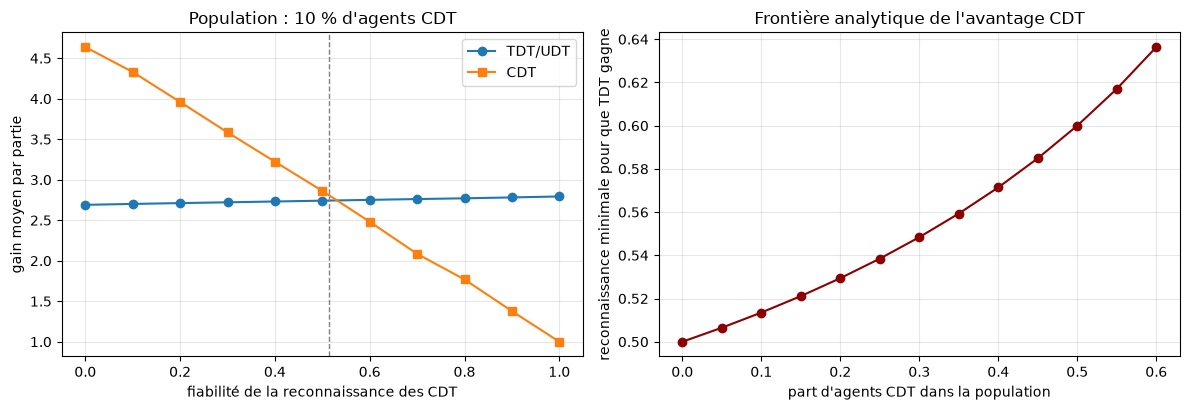


Robustesse du verdict initial sur 5 graines, reconnaissance = 0 :
  seed= 0 : TDT 2.690 | CDT 4.640 | CDT gagne : True
  seed= 1 : TDT 2.705 | CDT 4.618 | CDT gagne : True
  seed= 7 : TDT 2.701 | CDT 4.644 | CDT gagne : True
  seed=42 : TDT 2.706 | CDT 4.573 | CDT gagne : True
  seed=99 : TDT 2.702 | CDT 4.605 | CDT gagne : True


In [13]:
grille = []
for reconnaissance in np.linspace(0, 1, 11):
    ligne = simuler_population(part_cdt=0.1, reconnaissance=float(reconnaissance))
    ligne["avantage CDT"] = ligne["gain moyen CDT"] - ligne["gain moyen TDT"]
    grille.append(ligne)
frontiere = pd.DataFrame(grille)
print(frontiere[["reconnaissance", "gain moyen TDT", "gain moyen CDT", "avantage CDT"]]
      .round(3).to_string(index=False))

c = 0.1
r_seuil = (2 - c) / (4 - 3 * c)
print(f"\nSeuil analytique à part de CDT = {c} : r* = {r_seuil:.4f}")
print("En dessous de r*, CDT gagne plus ; au-dessus, la coopération conditionnelle paie.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(frontiere["reconnaissance"], frontiere["gain moyen TDT"], "o-", label="TDT/UDT")
axes[0].plot(frontiere["reconnaissance"], frontiere["gain moyen CDT"], "s-", label="CDT")
axes[0].axvline(r_seuil, color="grey", linestyle="--", linewidth=1)
axes[0].set_xlabel("fiabilité de la reconnaissance des CDT")
axes[0].set_ylabel("gain moyen par partie")
axes[0].set_title("Population : 10 % d'agents CDT")
axes[0].legend()
axes[0].grid(alpha=0.3)

parts = np.linspace(0.0, 0.6, 13)
seuils = [(2 - p) / (4 - 3 * p) for p in parts]
axes[1].plot(parts, seuils, "o-", color="darkred")
axes[1].set_xlabel("part d'agents CDT dans la population")
axes[1].set_ylabel("reconnaissance minimale pour que TDT gagne")
axes[1].set_title("Frontière analytique de l'avantage CDT")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nRobustesse du verdict initial sur 5 graines, reconnaissance = 0 :")
for graine in [0, 1, 7, 42, 99]:
    r = simuler_population(part_cdt=0.1, reconnaissance=0.0, seed=graine)
    print(f"  seed={graine:2d} : TDT {r['gain moyen TDT']:.3f} | CDT {r['gain moyen CDT']:.3f} "
          f"| CDT gagne : {r['gain moyen CDT'] > r['gain moyen TDT']}")


### Lecture du résultat — la frontière du « 2TDT-1CDT »

Le résultat de Dai n'est **pas** « CDT bat toujours UDT ». C'est un résultat conditionnel à une
hypothèse précise, que son énoncé contient : *nobody knows who the CDT agents are*. Le balayage
le montre :

- à **reconnaissance nulle**, l'agent coopératif coopère avec tout le monde, y compris avec les
  CDT qui le trahissent : son gain est $(1-c)\times3$, contre $(1-c)\times5+c$ pour un CDT ;
- quand la reconnaissance $r$ progresse, le coopérateur **conditionnel** cesse de nourrir les CDT :
  son gain devient $(1-c)\,3 + c\,r$, celui d'un CDT devient $(1-c)(5-4r) + c$. L'ordre s'inverse
  au seuil $r^* = \dfrac{2-c}{4-3c}$, soit $r^*\approx0{,}514$ à $c=0{,}1$ — la simulation bascule
  entre 0,5 et 0,6 ;
- plus la part de CDT augmente, **plus le seuil monte** ($r^*$ passe de 0,500 à $c\to0$ à environ
  0,636 à $c=0{,}6$) : dans une population très défectionniste, coopérer même avec une bonne
  reconnaissance ne suffit plus à devancer les CDT, parce que les occasions de coopération
  mutuelle se raréfient.

Le graphique de droite donne cette frontière analytiquement ; celui de gauche la retrouve par
simulation. C'est la différence entre **coopérer par principe** et **coopérer sous condition** :
le problème n° 4 de Dai punit la première, pas nécessairement la seconde. Et il ne dit rien d'une
population où les types sont parfaitement visibles ($r=1$), où la coopération conditionnelle
gagne nettement.


## 8. Exercices

Trois exercices, du plus mécanique au plus ouvert. Les stubs s'exécutent tels quels (convention
C.1) ; remplacez les `None` par vos calculs et comparez aux indications.

### Exercice 1 — Le pari du tabagisme dépend-il du gène omnipotent ?

Notre cas de Fisher suppose $S=G$ : le gène détermine totalement le fait de fumer. Relâchez cette
hypothèse : avec probabilité $\varepsilon$, l'agent fume **contre** son gène.

1. Écrivez `monde_tabagisme_libere(epsilon)` (on pourra réutiliser `monde_tabagisme` et modifier
   la CPT de $S$ : $S = G$ avec probabilité $1-\varepsilon$, $S = 1-G$ sinon).
2. Vérifiez que $P(C\mid S)$ **change** : les conditionnelles ne sont plus 0,6/0,2, alors que
   l'effet causal reste nul. Que faut-il recalculer pour comparer à l'article ?
3. Montrez que CDT recommande toujours de fumer, pour tout $\varepsilon$, alors que la
   recommandation d'EDT peut basculer. À quel $\varepsilon$ ?

*Indication* : la valeur de CDT ne dépend que de $P(C\mid do(S))$ et de $J$ ; celle d'EDT dépend
de la force de l'association résiduelle.


In [14]:
def monde_tabagisme_libere(epsilon: float) -> SCM:
    """Exercice 1 : cas de Fisher où le gène ne détermine plus totalement le tabac.

    À compléter : repartir de monde_tabagisme(fisher=True), puis remplacer la CPT de S par
    S = G avec probabilité 1 - epsilon, S = 1 - G sinon. Le mécanisme devient stochastique ;
    pour garder des mécanismes déterministes, introduire un bruit U_S explicite.
    """
    resultat = None  # TODO etudiant : construire et renvoyer le SCM
    return resultat


# Une fois le monde construit, ces lignes comparent les règles :
# monde = monde_tabagisme_libere(0.1)
# print(monde.prob({"C": 1}, given={"S": 1}), monde.prob({"C": 1}, given={"S": 0}))
# print(comparer_regles(monde, utilite_tabagisme))
print("Exercice 1 à compléter : stub exécutable, aucune erreur volontaire.")


Exercice 1 à compléter : stub exécutable, aucune erreur volontaire.


### Exercice 2 — Où la réduction CCDT = EDT cesse-t-elle d'être mécanique ?

La réduction repose sur une **description** des conséquences. Testez-la :

1. Dans le cas de Fisher, retirez $J$ des composantes retenues : `ev_ccdt(..., composantes=("C",))`.
   Que devient CCDT ? Pourquoi est-ce cohérent avec le §5 de Mohajeri ?
2. Ajoutez à la conséquence une composante **causée mais indépendante de l'utilité** (par exemple
   $J$ avec utilité nulle) : la réduction revient-elle ? Qu'est-ce que cela dit du rôle de la
   notion d'« adéquatement spécifié » ?
3. Dans Newcomb, décrivez la conséquence comme $(M, A)$ au lieu de $M$ seul : l'acte devient une
   composante de sa propre conséquence. La réduction est-elle restaurée ? Discutez si ce geste
   est une tricherie de description ou une bonne modélisation.

*Indication* : la question n'est pas « quelle règle est la bonne ? » mais « qui choisit les
composantes ? ».


In [15]:
# Exercice 2 : les trois appels à compléter et à commenter.
resultat_2a = None  # TODO etudiant : CCDT dans Fisher avec composantes=("C",) seulement
resultat_2b = None  # TODO etudiant : utilité qui ignore J, avec composantes=("C", "J")
resultat_2c = None  # TODO etudiant : Newcomb avec la conséquence (M, A) — réfléchir à la fonction utilite

# Exemple de squelette pour 2a :
# calc, detail = ev_ccdt_detail(fisher, utilite_tabagisme, "S", 1, ("C",))
# print(calc, detail)
print("Exercice 2 à compléter : trois variantes de la description des conséquences.")


Exercice 2 à compléter : trois variantes de la description des conséquences.


### Exercice 3 — Une population qui apprend

Le verdict « CDT s'en sort mieux » est un résultat **à politiques figées**. Prolongez-le :

1. Faites varier la part de CDT de 0 à 60 % et mesurez le gain moyen des deux types à
   reconnaissance nulle : l'avantage CDT décline-t-il comme le prédit la formule ?
2. Ajoutez une **réplication proportionnelle au gain** : après chaque génération, la part de CDT
   est multipliée par son gain relatif, puis renormalisée. Sur 30 générations, que devient la
   population ? Les agents TDT disparaissent-ils ?
3. Ajoutez une petite reconnaissance ($r=0{,}1$) : la dynamique change-t-elle de sens ?

*Indication* : le code de `simuler_population` renvoie déjà les deux gains moyens ; il suffit
d'itérer sur `part_cdt`. Discutez en quoi cette dynamique est un **modèle de sélection**, pas une
preuve que « CDT est la meilleure théorie » : elle mesure la fitness d'une politique dans un
environnement, pas sa rationalité.


In [16]:
# Exercice 3 : dynamique de population, à compléter.
def generation_suivante(part_cdt: float, reconnaissance: float = 0.0) -> float:
    """Nouvelle part de CDT après réplication proportionnelle au gain moyen."""
    nouvelle_part = None  # TODO etudiant : appeler simuler_population et renormaliser
    return nouvelle_part if nouvelle_part is not None else part_cdt


trajectoire = []
part = 0.1
for _ in range(30):
    trajectoire.append(part)
    part = generation_suivante(part)
print("Exercice 3 à compléter : la trajectoire ci-dessous reste constante tant que le stub n'est")
print("pas implémenté.")
print([round(p, 4) for p in trajectoire[:6]], "...")


Exercice 3 à compléter : la trajectoire ci-dessous reste constante tant que le stub n'est
pas implémenté.
[0.1, 0.1, 0.1, 0.1, 0.1, 0.1] ...


## 9. Ce que ce carnet a établi — et ses limites

**Résultats mesurés dans les sorties ci-dessus :**

1. Sur un SCM fini, EDT et CDT se calculent exactement par conditionnement et par intervention.
   Elles divergent dès qu'un confondeur relie l'acte à la conséquence (Fisher), et dès que l'acte
   est une preuve sur soi (Egan) ou sur une prédiction (Newcomb).
2. L'organe `dowhy` retrouve le contraste causal nul du cas de Fisher sur échantillon, alors que
   le contraste brut est le même dans les deux mondes.
3. La formule (1) de CCDT, lue « sous $do(a)$ » avec un test directionnel d'influence,
   **reproduit les quatre valeurs publiées** par Mohajeri (5 et 8, deux fois) et **coincide avec
   EDT** sur les cas de Fisher, Egan et une famille de 40 mondes générés.
4. Le « 2TDT-1CDT » de Dai est reproduit : à reconnaissance nulle des types, les agents CDT
   gagnent plus que les agents coopératifs ; l'avantage disparaît au seuil analytique $r^*$.

**Limites à ne pas oublier :**

- *La réduction CCDT = EDT n'est pas démontrée ici en général.* Elle est vérifiée sur une classe
  de modèles, avec une définition opérationnelle de « $a\triangleright C_j$ » et des conséquences
  décrites comme conjonctions de composantes. D'autres formalisations de l'influence causale sont
  possibles ; le §4 de Mohajeri montre d'ailleurs que les calculs d'Edgington elle-même ne
  suivent pas toujours la formule (1).
- *Le cas d'Egan utilise notre paramétrage chiffré* (payoffs ±1000, prior 0,1), pas des valeurs
  citées d'un texte : la structure est celle d'Egan, les nombres sont un choix pédagogique.
- *La « corrélation logique » UDT est représentée par une disposition commune et des bruits
  indépendants.* C'est un SCM ordinaire : il illustre la conséquence décisionnelle de l'idée, il
  ne formalise pas la corrélation entre calculs, qui est le cœur difficile du sujet (problèmes 6
  et 7 de Dai).
- *Le gain moyen n'est pas la rationalité.* La simulation de population mesure une fitness dans
  un environnement donné ; elle ne départage pas les théories normatives. Dai lui-même pose le
  résultat comme une question ouverte (« What does this imply? »), pas comme un verdict.

**Pour aller plus loin** : les autres problèmes de Dai (valeurs indexicales, anthropique,
conditionnels logiques) ne se prêtent pas à une simulation jouet de ce genre ; ils demandent un
formalisme plus riche que celui de ce carnet. La couche formelle de l'arc
([`decision_theory_lean`](../decision_theory_lean/)) certifie d'autres piliers (utilité espérée
vNM, cohérence de de Finetti, escompte de Gittins) : une formalisation des règles de décision
comparées serait un prolongement naturel, non couvert ici.


## Références

Sources archivées au gisement partagé `G:\Mon Drive\MyIA\IA\Bibliographie IA\` (copies lues avant
rédaction ; les PDF ne sont pas committés dans le dépôt) :

- **Dai, Wei (2023).** *UDT shows that decision theory is more puzzling than ever*, AI Alignment
  Forum, 13 septembre 2023 — `Probabilistic\2023 - Dai - UDT shows that decision theory is more
  puzzling than ever.pdf`. Utilisé ici pour le problème n° 4 (« 2TDT-1CDT ») et pour la liste des
  problèmes ouverts rappelée en conclusion.
- **Mohajeri, Mostafa (preprint 2023 ; publié 2024).** *Conditional causal decision theory reduces
  to evidential decision theory*, Analytic Philosophy **65**, 93-106, DOI 10.1111/phib.12298 — `Probabilistic\2023 - Mohajeri -
  Conditional causal decision theory reduces to evidential decision theory.pdf`. Formule (1) de
  CCDT, exemples chiffrés (tableau 1, équations 4-5 et 8-9), notion de « problème adéquatement
  spécifié » et argument de réduction du §5.

Travaux discutés par ces deux sources et mobilisés dans le carnet (non reproduits) :

- Edgington, Dorothy (2011). *Causation first: why causation is prior to counterfactuals*, in
  *Understanding Counterfactuals, Understanding Causation* — origine de la CCDT et des exemples
  du tabagisme.
- Egan, Andy (2007). *Some counterexamples to causal decision theory*, Philosophical Review
  116(1) — schéma de l'acte-preuve utilisé à la section 6.
- Wedgwood, Ralph (2013). *Gandalf's solution to the Newcomb problem* — Benchmark Theory,
  mentionnée comme alternative non traitée ici.

Outils : calcul exact par énumération (numpy/pandas) ; [`dowhy`](https://www.pywhy.org/dowhy/)
pour l'identification et l'estimation causales (section 3) ; figures matplotlib.

Carnet produit dans le cadre du réservoir de distillations bibliographiques de l'Epic #14468
(cible et critères de sortie : issue #22778).
